In [14]:
import pandas as pd
import seaborn as sns
from sklearn.model_selection import cross_val_score
from sklearn.tree import DecisionTreeClassifier, export_text

train = pd.read_csv('../data/Task2/yeast.csv')
train.name = train.name.astype('category')

In [15]:
train

,mcg,gvh,alm,mit,erl,pox,vac,nuc,name
0,0.58,0.61,0.47,0.13,0.5,0.0,0.48,0.22,MIT
1,0.43,0.67,0.48,0.27,0.5,0.0,0.53,0.22,MIT
2,0.64,0.62,0.49,0.15,0.5,0.0,0.53,0.22,MIT
3,0.58,0.44,0.57,0.13,0.5,0.0,0.54,0.22,NUC
4,0.42,0.44,0.48,0.54,0.5,0.0,0.48,0.22,MIT
...,...,...,...,...,...,...,...,...,...
1479,0.81,0.62,0.43,0.17,0.5,0.0,0.53,0.22,ME2
1480,0.47,0.43,0.61,0.40,0.5,0.0,0.48,0.47,NUC
1481,0.67,0.57,0.36,0.19,0.5,0.0,0.56,0.22,ME2
1482,0.43,0.40,0.60,0.16,0.5,0.0,0.53,0.39,NUC


In [16]:
train.info()
train.describe()

<class 'pandas.DataFrame'>
RangeIndex: 1484 entries, 0 to 1483
Data columns (total 9 columns):
 #   Column  Non-Null Count  Dtype   
---  ------  --------------  -----   
 0   mcg     1484 non-null   float64 
 1   gvh     1484 non-null   float64 
 2   alm     1484 non-null   float64 
 3   mit     1484 non-null   float64 
 4   erl     1484 non-null   float64 
 5   pox     1484 non-null   float64 
 6   vac     1484 non-null   float64 
 7   nuc     1484 non-null   float64 
 8   name    1484 non-null   category
dtypes: category(1), float64(8)
memory usage: 94.7 KB


,mcg,gvh,alm,mit,erl,pox,vac,nuc
count,1484.000000,1484.000000,1484.000000,1484.000000,1484.000000,1484.000000,1484.000000,1484.000000
mean,0.500121,0.499933,0.500034,0.261186,0.504717,0.007500,0.499885,0.276199
std,0.137299,0.123924,0.086670,0.137098,0.048351,0.075683,0.057797,0.106491
min,0.110000,0.130000,0.210000,0.000000,0.500000,0.000000,0.000000,0.000000
25%,0.410000,0.420000,0.460000,0.170000,0.500000,0.000000,0.480000,0.220000
50%,0.490000,0.490000,0.510000,0.220000,0.500000,0.000000,0.510000,0.220000
75%,0.580000,0.570000,0.550000,0.320000,0.500000,0.000000,0.530000,0.300000
max,1.000000,1.000000,1.000000,1.000000,1.000000,0.830000,0.730000,1.000000


In [17]:
train.name.value_counts()

name
CYT    463
NUC    429
MIT    244
ME3    163
ME2     51
ME1     44
EXC     35
VAC     30
POX     20
ERL      5
Name: count, dtype: int64

<Axes: >

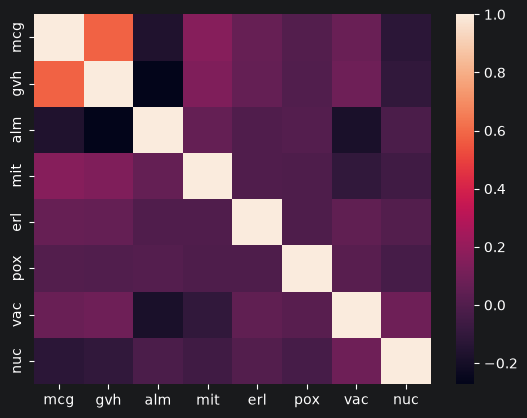

In [18]:
sns.heatmap(train.iloc[:, :8].corr())

In [39]:
x = train.drop(columns=['name'])
y = train['name']

dt = DecisionTreeClassifier(criterion='entropy', min_samples_leaf=10)
dt.fit(x, y)
print(export_text(dt, feature_names=x.columns))

|--- alm <= 0.44
|   |--- mcg <= 0.67
|   |   |--- alm <= 0.38
|   |   |   |--- mit <= 0.20
|   |   |   |   |--- vac <= 0.52
|   |   |   |   |   |--- alm <= 0.34
|   |   |   |   |   |   |--- mcg <= 0.38
|   |   |   |   |   |   |   |--- class: ME3
|   |   |   |   |   |   |--- mcg >  0.38
|   |   |   |   |   |   |   |--- class: ME3
|   |   |   |   |   |--- alm >  0.34
|   |   |   |   |   |   |--- mit <= 0.15
|   |   |   |   |   |   |   |--- class: ME3
|   |   |   |   |   |   |--- mit >  0.15
|   |   |   |   |   |   |   |--- class: ME3
|   |   |   |   |--- vac >  0.52
|   |   |   |   |   |--- alm <= 0.34
|   |   |   |   |   |   |--- class: ME3
|   |   |   |   |   |--- alm >  0.34
|   |   |   |   |   |   |--- class: ME3
|   |   |   |--- mit >  0.20
|   |   |   |   |--- mcg <= 0.56
|   |   |   |   |   |--- alm <= 0.37
|   |   |   |   |   |   |--- gvh <= 0.61
|   |   |   |   |   |   |   |--- class: ME3
|   |   |   |   |   |   |--- gvh >  0.61
|   |   |   |   |   |   |   |--- class: ME3
|   |

In [42]:
scores = cross_val_score(dt, x, y, cv=5, scoring='f1_weighted')
print(scores)

[0.53611712 0.54326361 0.5620522  0.51672625 0.53786374]
